# Estimador de riesgo de grooming basado en la edad de las voces

> ⚠️ **Aviso.** Este modelo es una **alerta / estimador de riesgo**, **no un decisor**.
> Solo estima si en un audio parece haber una persona menor de edad hablando con una
> persona adulta. Eso por sí mismo **no es grooming**: padres, docentes, médicos o
> entrenadores generan exactamente la misma señal. Cualquier alerta debe pasar a
> **revisión humana especializada**. Ver `CLAUDE.md`.

**Objetivo.** A partir de **solo audio**:

1. Separar a los hablantes (diarización ligera).
2. Estimar para cada uno la probabilidad de ser **niño (≤12)**, **adolescente (13–17)** o **adulto (≥18)**.
3. Combinar esas probabilidades en un puntaje de riesgo: si con certeza hay un niño
   y un adulto distintos → **90 %**; adolescente + adulto → **60 %**; con incertidumbre
   el riesgo se escala proporcionalmente.

**Plan del notebook**

| # | Sección |
|---|---------|
| 0 | Datos: `construccion_dataset.ipynb` (ejecutar antes) |
| 1 | Configuración |
| 2 | Carga del dataset unido |
| 3 | Partición por hablante (verificación) |
| 4 | Extracción de características + aumentación |
| 5 | Entrenamiento de 3 modelos (+1 referencia) |
| 6 | Evaluación y selección del mejor |
| 7 | Auditoría de sesgo por corpus |
| 8 | Guardado del mejor modelo |
| 9 | Prueba de punta a punta con conversaciones simuladas |

## 1. Configuración

El dataset se construye en `notebooks/construccion_dataset.ipynb` (ENNI + Common Voice →
`datasets/merged/`), que hay que ejecutar antes que este notebook.

Entrenamiento local: en Apple Silicon todo corre en **CPU**. Con clips de longitud variable, MPS
recompila los kernels en cada forma nueva y WavLM resulta ~3× más lento que en CPU; ECAPA ya
corría en CPU (SpeechBrain tiene operaciones no soportadas en MPS). Si `SUBSAMPLE` no es `None`,
se usa una muestra pequeña para comprobar que todo funciona antes del entrenamiento completo.

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from grooming_risk.config import CLASSES, FEATURES_DIR, MODELS_DIR, SAMPLE_RATE, MIN_SEGMENT_SEC
from grooming_risk.audio import load_audio, trim_silence, augment
from grooming_risk.features import build_extractor, best_device
from grooming_risk.pipeline import reorder_proba, save_bundle, GroomingRiskAnalyzer
from grooming_risk.risk import compute_risk

SEED = 42
rng = np.random.default_rng(SEED)
DEVICE = best_device()
if DEVICE == "mps":
    DEVICE = "cpu"   # ver nota arriba: en MPS WavLM es más lento con longitudes variables

MERGED_DIR = ROOT / "datasets" / "merged"   # generado por construccion_dataset.ipynb
SUBSAMPLE = None          # p.ej. 600 para una corrida rápida de prueba
AUG_COPIES = 1            # copias aumentadas por clip de entrenamiento (todas las clases por igual)
EXTRACTORS = ["handcrafted", "ecapa", "wavlm"]
RUN_AUDEERING_REFERENCE = False   # True descarga ~1.2 GB; solo evaluación
FEATURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print("device:", DEVICE)

device: cpu


## 2. Dataset

Se usa el dataset unido de `datasets/merged/` (ver `construccion_dataset.ipynb` para el análisis
completo de cada corpus):

| Corpus | Clase | Edad | Hablantes | Comentario |
|---|---|---|---|---|
| **ENNI child speech synthesis** (TalkBank FASA ENNI) | `nino` | exacta, 4–10 años | 348 | habla **sintetizada**, inglés |
| **Common Voice** (versión Kaggle 2017) `teens` | `adolescente` | "< 19" → 16 | 25 grupos | etiqueta ruidosa (incluye 18–19) |
| **Common Voice** `twenties`+ | `adulto` | centro de la década | 152 grupos | submuestreado para balancear |

Todo está ya en WAV 16 kHz mono y con la partición train/val/test **por hablante** hecha.
Common Voice no trae identificador de hablante: su `speaker_id` es un pseudo-hablante
`(década, género, acento)`, que nunca reparte a una misma persona entre particiones.

**Riesgos conocidos de esta mezcla**
- *Confusión por canal*: **todos** los niños vienen de ENNI (sintético, limpio) y todos los demás de
  Common Voice (micrófonos caseros). El modelo puede aprender el canal en vez de la edad.
  Mitigaciones: normalización de volumen, aumentación de canal y la auditoría de la sección 7.
  La mitigación real es añadir un corpus con niños **y** adultos en el mismo canal (p.ej.
  speechocean762, ver `data/README.md`).
- *Etiquetas ruidosas*: `teens` de Common Voice incluye 18–19 años.
- *Idioma*: solo inglés. Las pistas de edad (F0, formantes) son mayormente independientes del idioma,
  pero conviene añadir audio en el idioma de uso (p.ej. Common Voice en español).

In [2]:
df = pd.read_csv(MERGED_DIR / "metadata.csv")
df["path"] = df["path"].map(lambda p: str(MERGED_DIR / p))
if SUBSAMPLE:
    df = (df.sample(frac=1, random_state=SEED)
            .groupby("age_class").head(SUBSAMPLE // len(CLASSES))
            .reset_index(drop=True))
assert not df.empty, "No se encontró datasets/merged/metadata.csv: ejecuta construccion_dataset.ipynb"
print(f"{len(df)} clips, {df.speaker_id.nunique()} hablantes, {df.duration.sum() / 3600:.1f} h")
pd.crosstab(df.source, df.age_class, margins=True)

23893 clips, 524 hablantes, 27.7 h


age_class,adolescente,adulto,nino,All
source,,,,
common_voice,3960,9963,0,13923
enni,0,0,9970,9970
All,3960,9963,9970,23893


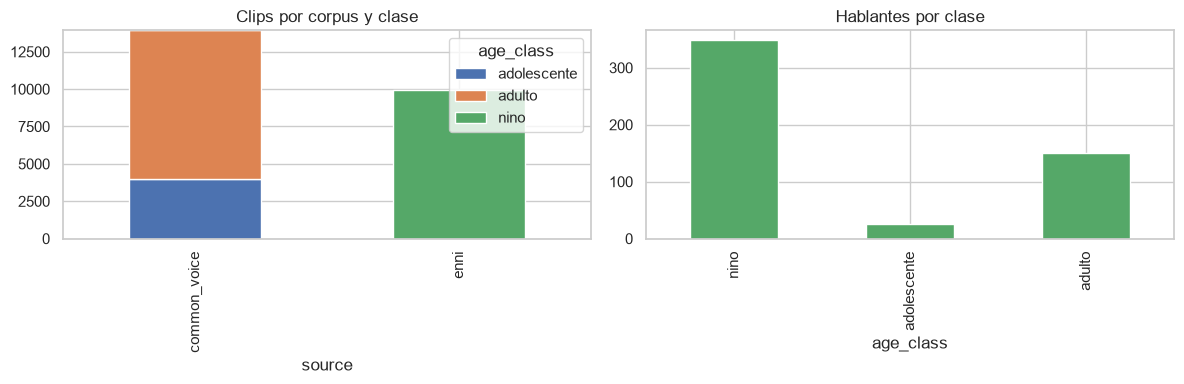

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.crosstab(df.source, df.age_class).plot.bar(stacked=True, ax=axes[0], title="Clips por corpus y clase")
df.groupby("age_class").speaker_id.nunique().reindex(CLASSES).plot.bar(ax=axes[1], title="Hablantes por clase", color="C2")
plt.tight_layout(); plt.show()

## 3. Partición por hablante

Un mismo hablante **nunca** aparece en dos particiones: si no, el modelo memorizaría voces y
las métricas serían irrealmente altas. La partición (~70 % train, ~15 % validación, ~15 % test,
repartiendo hablantes completos dentro de cada clase) viene hecha en `metadata.csv`; aquí solo se
verifica que no haya fuga.

In [4]:
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    inter = set(df[df.split == a].speaker_id) & set(df[df.split == b].speaker_id)
    assert not inter, f"Fuga de hablantes entre {a} y {b}"
display(pd.crosstab(df.split, df.age_class, margins=True))
pd.crosstab(df.split, df.age_class, values=df.speaker_id, aggfunc="nunique")

age_class,adolescente,adulto,nino,All
split,,,,
test,742,1532,1519,3793
train,2438,6904,6951,16293
val,780,1527,1500,3807
All,3960,9963,9970,23893


age_class,adolescente,adulto,nino
split,,,
test,4,24,53
train,14,105,240
val,7,22,55


## 4. Extracción de características

Se carga cada audio **una sola vez** y se pasa por los tres extractores:

- Se recorta a máximo 8 s, se normaliza el volumen y se quitan silencios.
- Clips < 1 s se descartan (no hay suficiente voz para estimar edad).
- Cada clip de **entrenamiento** recibe `AUG_COPIES` versiones aumentadas (canal telefónico,
  ruido, saturación). Se aumentan **todas las clases por igual** para que "audio ruidoso" no se
  convierta en una pista de clase. No se usa *pitch shift*: alteraría la señal de edad.

Las características se guardan en `data/features/` para no recalcularlas.

In [5]:
def cache_path(name):
    tag = f"_sub{SUBSAMPLE}" if SUBSAMPLE else ""
    return FEATURES_DIR / f"{name}{tag}.npz"

def extract_features(df, names):
    todo = [n for n in names if not cache_path(n).exists()]
    if todo:
        extractors = {n: build_extractor(n, DEVICE) for n in todo}
        dims, X, X_aug = {}, {n: [None] * len(df) for n in todo}, {n: [None] * len(df) for n in todo}
        aug_rng = np.random.default_rng(SEED)
        for i, row in enumerate(tqdm(df.itertuples(), total=len(df), desc="extrayendo")):
            try:
                wav = trim_silence(load_audio(row.path, max_sec=8.0))
            except Exception as exc:
                print("error", row.path, exc); continue
            if len(wav) < MIN_SEGMENT_SEC * SAMPLE_RATE:
                continue
            augs = [augment(wav, aug_rng) for _ in range(AUG_COPIES)] if row.split == "train" else []
            for n, ext in extractors.items():
                X[n][i] = ext.extract(wav)
                X_aug[n][i] = [ext.extract(a) for a in augs]
        for n in todo:
            d = next(v for v in X[n] if v is not None).shape[0]
            feats = np.stack([v if v is not None else np.full(d, np.nan, np.float32) for v in X[n]])
            aug = np.full((len(df), AUG_COPIES, d), np.nan, np.float32)
            for i, lst in enumerate(X_aug[n]):
                for k, v in enumerate(lst or []):
                    aug[i, k] = v
            np.savez_compressed(cache_path(n), X=feats, X_aug=aug, paths=df.path.to_numpy())
    out = {}
    for n in names:
        z = np.load(cache_path(n), allow_pickle=True)
        assert (z["paths"] == df.path.to_numpy()).all(), f"Caché {n} desalineada: bórrala y recalcula"
        out[n] = (z["X"], z["X_aug"])
    return out

FEATS = extract_features(df, EXTRACTORS)
valid = ~np.isnan(FEATS[EXTRACTORS[0]][0]).any(1)
print(f"clips válidos: {valid.sum()} / {len(df)}")
{n: X.shape for n, (X, _) in FEATS.items()}

/Users/davidcervantes/Documents/Reconocimiento de Voz/riesgo-grooming-audio/.venv/lib/python3.12/site-packages/speechbrain/utils/autocast.py:188: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  wrapped_fwd = torch.cuda.amp.custom_fwd(fwd, cast_inputs=cast_inputs)


extrayendo:   0%|          | 0/23893 [00:00<?, ?it/s]

clips válidos: 23560 / 23893


{'handcrafted': (23893, 118), 'ecapa': (23893, 192), 'wavlm': (23893, 1536)}

**Validación exploratoria de la hipótesis acústica.** La primera característica handcrafted es
la media de log-F0. Si la hipótesis es correcta, los niños deberían tener el tono más alto.

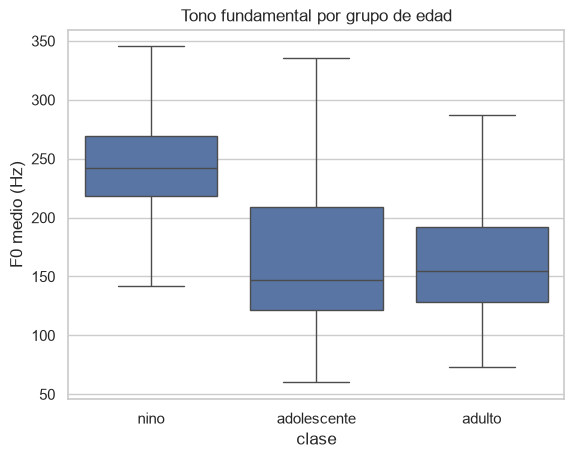

In [6]:
f0 = np.exp(FEATS["handcrafted"][0][:, 0])
plot_df = pd.DataFrame({"F0 medio (Hz)": f0, "clase": df.age_class})[valid]
sns.boxplot(data=plot_df, x="clase", y="F0 medio (Hz)", order=CLASSES, showfliers=False)
plt.title("Tono fundamental por grupo de edad"); plt.show()

## 5. Modelos y justificación

Se entrenan **tres familias complementarias**, de lo más interpretable a lo más potente,
para poder justificar con datos cuál desplegar:

| Modelo | Representación | Clasificador | Por qué |
|---|---|---|---|
| **A. Acústico clásico** | ~130 rasgos: F0, formantes F1–F3, MFCC+Δ, espectrales | Gradient Boosting (`HistGradientBoosting`) | La fisiología explica la edad: los niños tienen cuerdas vocales y tracto vocal más cortos → F0 y formantes más altos. Los árboles capturan umbrales no lineales (p.ej. F0 alto + F1 alto) y son interpretables. Línea base barata que corre en cualquier CPU. |
| **B. ECAPA-TDNN + SVM** | Embedding de hablante de 192 dims (SpeechBrain, VoxCeleb) | SVM con kernel RBF | ECAPA es el estado del arte en reconocimiento de hablante; su embedding resume la "huella vocal", que incluye edad y sexo. Es compacto, así que un SVM con pocos datos de menores generaliza bien (margen máximo). Además se reutiliza para la diarización. |
| **C. WavLM + regresión logística** | Capas 3–8 de WavLM-base-plus, pooling media+desv. (1536 dims) | Regresión logística (*linear probe*) | Modelo autosupervisado entrenado con 94 k h; líder del benchmark SUPERB en tareas de hablante y paralingüística. Sus capas intermedias codifican edad/sexo. Un clasificador lineal sobre representaciones congeladas es eficiente en datos y evita sobreajustar con pocos menores (no hacemos *fine-tuning* completo por el tamaño del dataset y para entrenar en local). |
| *D. Referencia audEERING* | wav2vec2-large afinado para edad | — (zero-shot) | Modelo publicado de estimación de edad. Sirve de cota externa: ¿nuestros modelos superan a uno ya existente? Licencia no comercial → no se despliega. |

**Decisiones comunes**
- `class_weight="balanced"`: hay muchos menos menores que adultos.
- Hiperparámetros elegidos en **validación** con F1-macro.
- **Calibración sigmoide** sobre validación: el puntaje de riesgo multiplica probabilidades, así que
  estas deben ser fiables (un 0.9 debe significar ~90 % de aciertos), no solo bien ordenadas.

In [7]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

y = df.age_class.to_numpy()
idx = {s: np.where((df.split == s).to_numpy() & valid)[0] for s in ["train", "val", "test"]}

def get_xy(name, split, with_aug=False):
    X, X_aug = FEATS[name]
    i = idx[split]
    Xs, ys = [X[i]], [y[i]]
    if with_aug:
        for k in range(X_aug.shape[1]):
            ok = ~np.isnan(X_aug[i, k]).any(1)
            Xs.append(X_aug[i, k][ok]); ys.append(y[i][ok])
    return np.vstack(Xs), np.concatenate(ys)

MODELS = {
    "A_handcrafted_gbm": ("handcrafted",
        HistGradientBoostingClassifier(max_iter=400, class_weight="balanced", early_stopping=True,
                                       random_state=SEED),
        {"learning_rate": [0.05, 0.1], "max_depth": [None, 6], "l2_regularization": [0.0, 1.0]}),
    "B_ecapa_svm": ("ecapa",
        make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", random_state=SEED)),
        {"svc__C": [0.3, 1, 3, 10], "svc__gamma": ["scale"]}),
    "C_wavlm_logreg": ("wavlm",
        make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)),
        {"logisticregression__C": [0.001, 0.01, 0.1, 1.0]}),
}
MODELS = {k: v for k, v in MODELS.items() if v[0] in EXTRACTORS}

def calibrate(model, X, y):
    try:
        from sklearn.frozen import FrozenEstimator   # scikit-learn >= 1.6
        cal = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid")
    except ImportError:
        cal = CalibratedClassifierCV(model, method="sigmoid", cv="prefit")
    return cal.fit(X, y)

def metrics(y_true, proba):
    y_pred = np.array(CLASSES)[proba.argmax(1)]
    rep = classification_report(y_true, y_pred, labels=CLASSES, output_dict=True, zero_division=0)
    minor = y_true != "adulto"
    p_minor = 1 - proba[:, CLASSES.index("adulto")]
    return {
        "f1_macro": f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        **{f"recall_{c}": rep[c]["recall"] for c in CLASSES},
        "auc_menor_vs_adulto": roc_auc_score(minor, p_minor) if 0 < minor.mean() < 1 else np.nan,
    }

In [8]:
trained, val_scores = {}, {}
for name, (feat, base, grid) in MODELS.items():
    Xtr, ytr = get_xy(feat, "train", with_aug=True)
    Xva, yva = get_xy(feat, "val")
    best = (-1, None, None)
    for params in tqdm(list(ParameterGrid(grid)), desc=name):
        m = clone(base).set_params(**params).fit(Xtr, ytr)
        score = f1_score(yva, m.predict(Xva), average="macro")
        if score > best[0]:
            best = (score, params, m)
    print(f"{name}: mejor F1-macro val = {best[0]:.3f} con {best[1]}")
    trained[name] = {"feat": feat, "model": calibrate(best[2], Xva, yva), "params": best[1]}
    val_scores[name] = best[0]

A_handcrafted_gbm:   0%|          | 0/8 [00:00<?, ?it/s]

A_handcrafted_gbm: mejor F1-macro val = 0.706 con {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_depth': 6}


B_ecapa_svm:   0%|          | 0/4 [00:00<?, ?it/s]

B_ecapa_svm: mejor F1-macro val = 0.745 con {'svc__C': 0.3, 'svc__gamma': 'scale'}


C_wavlm_logreg:   0%|          | 0/4 [00:00<?, ?it/s]

C_wavlm_logreg: mejor F1-macro val = 0.767 con {'logisticregression__C': 0.001}


## 6. Evaluación en test

Métricas:
- **F1-macro** y **balanced accuracy**: tratan a las tres clases por igual pese al desbalance.
- **Recall de `nino`**: el error más grave para una alerta es no detectar al menor (falso negativo).
- **AUC menor-vs-adulto**: calidad de la probabilidad `P(menor)` que alimenta el riesgo.

Se reporta a nivel de **clip** y a nivel de **hablante** (promediando las probabilidades de todos
sus clips, que es como funciona la API con un hablante diarizado).

Ojo con el nivel *hablante* en este dataset: en Common Voice cada "hablante" es un grupo
demográfico con muchas personas, y en test solo hay 4 grupos de adolescentes, así que esa
métrica es muy ruidosa. Por eso la selección usa el nivel **clip**.

In [9]:
results, test_probas = [], {}
test_df_valid = df.iloc[idx["test"]]
for name, t in trained.items():
    Xte, yte = get_xy(t["feat"], "test")
    proba = reorder_proba(t["model"].predict_proba(Xte), t["model"].classes_)
    test_probas[name] = proba
    spk = (pd.DataFrame(proba, columns=CLASSES).assign(spk=test_df_valid.speaker_id.values, y=yte)
             .groupby("spk").agg({**{c: "mean" for c in CLASSES}, "y": "first"}))
    results.append({"modelo": name, "nivel": "clip", **metrics(yte, proba)})
    results.append({"modelo": name, "nivel": "hablante", **metrics(spk.y.to_numpy(), spk[CLASSES].to_numpy())})

if RUN_AUDEERING_REFERENCE:
    from grooming_risk.features import AudeeringAgeModel
    ref = AudeeringAgeModel(DEVICE)
    proba = np.stack([ref.predict_proba(trim_silence(load_audio(p, max_sec=8.0)))
                      for p in tqdm(test_df_valid.path, desc="audeering")])
    test_probas["D_audeering_zero_shot"] = proba
    results.append({"modelo": "D_audeering_zero_shot", "nivel": "clip", **metrics(test_df_valid.age_class.to_numpy(), proba)})

res = pd.DataFrame(results).set_index(["modelo", "nivel"]).round(3)
res

f1_macro  balanced_acc  recall_nino  \
modelo            nivel                                           
A_handcrafted_gbm clip         0.708         0.710        0.997   
                  hablante     0.634         0.653        1.000   
B_ecapa_svm       clip         0.817         0.814        0.987   
                  hablante     0.837         0.819        1.000   
C_wavlm_logreg    clip         0.786         0.778        1.000   
                  hablante     0.837         0.819        1.000   

                            recall_adolescente  recall_adulto  \
modelo            nivel                                         
A_handcrafted_gbm clip                   0.261          0.872   
                  hablante               0.000          0.958   
B_ecapa_svm       clip                   0.604          0.852   
                  hablante               0.500          0.958   
C_wavlm_logreg    clip                   0.427          0.906   
                  hablante               0.500          0.958   

                            auc_menor_vs_adulto  
modelo            nivel                          
A_handcrafted_gbm clip                    0.870  
                  hablante                0.986  
B_ecapa_svm       clip                    0.943  
                  hablante                0.998  
C_wavlm_logreg    clip                    0.940  
                  hablante                0.993

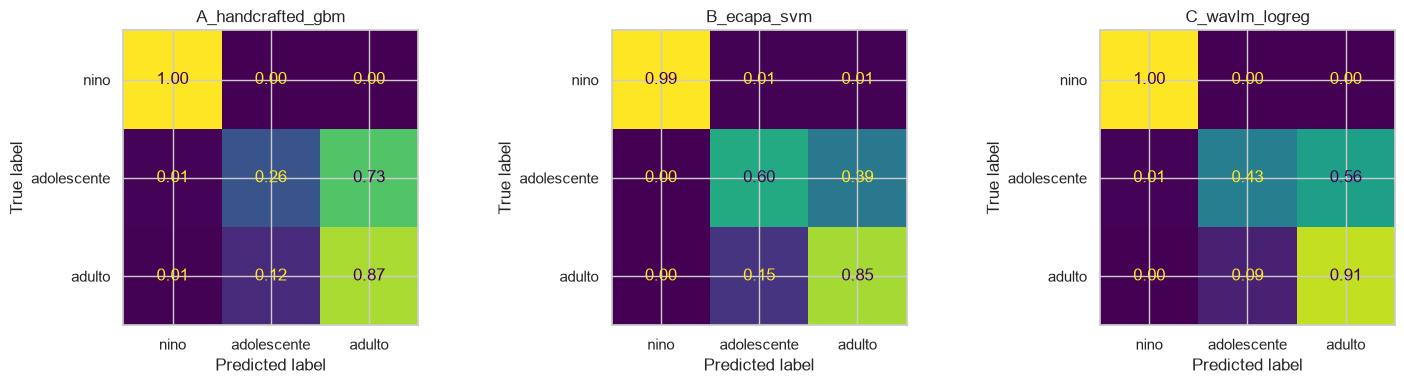

In [10]:
fig, axes = plt.subplots(1, len(test_probas), figsize=(5 * len(test_probas), 4))
yte = test_df_valid.age_class.to_numpy()
for ax, (name, proba) in zip(np.atleast_1d(axes), test_probas.items()):
    ConfusionMatrixDisplay.from_predictions(yte, np.array(CLASSES)[proba.argmax(1)], labels=CLASSES,
                                            normalize="true", values_format=".2f", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

### Selección del mejor modelo

Criterio: mayor **F1-macro a nivel de clip** en test; en caso de empate (±0.01) gana el de mayor
**recall de `nino`**. (Con hablantes reales y suficientes por clase convendría usar el nivel
hablante, que es la unidad de la API; aquí los pseudo-hablantes de Common Voice lo hacen poco
fiable.) La referencia de audEERING no es elegible (licencia no comercial y no fue entrenada por
nosotros).

In [11]:
cand = res.xs("clip", level="nivel").loc[list(trained)]
top = cand.f1_macro.max()
BEST = cand[cand.f1_macro >= top - 0.01].sort_values("recall_nino", ascending=False).index[0]
print("Mejor modelo:", BEST)
cand.sort_values("f1_macro", ascending=False)

Mejor modelo: B_ecapa_svm


,f1_macro,balanced_acc,recall_nino,recall_adolescente,recall_adulto,auc_menor_vs_adulto
modelo,,,,,,
B_ecapa_svm,0.817,0.814,0.987,0.604,0.852,0.943
C_wavlm_logreg,0.786,0.778,1.000,0.427,0.906,0.940
A_handcrafted_gbm,0.708,0.710,0.997,0.261,0.872,0.870


## 7. Auditoría de sesgo por canal

En este dataset clase y corpus están confundidos (`nino` = ENNI), así que la prueba clásica de
"¿se puede predecir el corpus?" equivale a predecir `nino` y no aporta información. Se hacen tres
comprobaciones:

1. **Rendimiento por corpus**: recall de cada clase dentro de cada corpus.
2. **Predictibilidad del corpus** (se mantiene como referencia: aquí siempre saldrá alta).
3. **Robustez al canal**: se degrada el audio de test con la misma aumentación de canal del
   entrenamiento (teléfono, ruido, saturación). Si el modelo usara "audio limpio = niño", el recall
   de `nino` caería mucho al ensuciar los clips de ENNI.

In [12]:
proba = test_probas[BEST]
by_src = []
for src, g in test_df_valid.assign(pred=np.array(CLASSES)[proba.argmax(1)]).groupby("source"):
    row = {"corpus": src, "n": len(g), "accuracy": (g.pred == g.age_class).mean()}
    row.update({f"recall_{c}": (g[g.age_class == c].pred == c).mean() if (g.age_class == c).any() else np.nan
                for c in CLASSES})
    by_src.append(row)
display(pd.DataFrame(by_src).round(3))

from sklearn.model_selection import cross_val_score, GroupKFold
if df.source[valid].nunique() > 1:
    feat = trained[BEST]["feat"]
    X_all = FEATS[feat][0][valid]
    src_acc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                              X_all, df.source[valid], groups=df.speaker_id[valid], cv=GroupKFold(5)).mean()
    print(f"Exactitud prediciendo el corpus con features '{feat}': {src_acc:.3f} "
          f"(azar ≈ {df.source[valid].value_counts(normalize=True).max():.3f})")
else:
    print("Solo hay un corpus: no aplica la prueba de predictibilidad del corpus.")

# 3. Robustez al canal: mismo test con audio degradado
ext = build_extractor(trained[BEST]["feat"], DEVICE)
deg_rng = np.random.default_rng(SEED)
X_deg = np.stack([ext.extract(augment(trim_silence(load_audio(p, max_sec=8.0)), deg_rng))
                  for p in tqdm(test_df_valid.path, desc="test degradado")])
proba_deg = reorder_proba(trained[BEST]["model"].predict_proba(X_deg), trained[BEST]["model"].classes_)
robustez = pd.DataFrame([{"audio": "original", **metrics(yte, proba)},
                         {"audio": "degradado", **metrics(yte, proba_deg)}]).set_index("audio")
robustez.round(3)

,corpus,n,accuracy,recall_nino,recall_adolescente,recall_adulto
0,common_voice,2217,0.773,NaN,0.604,0.852
1,enni,1507,0.987,0.987,NaN,NaN


Exactitud prediciendo el corpus con features 'ecapa': 0.988 (azar ≈ 0.579)


test degradado:   0%|          | 0/3724 [00:00<?, ?it/s]

,f1_macro,balanced_acc,recall_nino,recall_adolescente,recall_adulto,auc_menor_vs_adulto
audio,,,,,,
original,0.817,0.814,0.987,0.604,0.852,0.943
degradado,0.813,0.807,0.979,0.567,0.876,0.944


## 8. Guardado del mejor modelo

Se guarda un *bundle* `models/best_model.joblib` con el clasificador calibrado y el nombre del
extractor que necesita, más `models/model_card.json` con las métricas. La API y Docker leen
este bundle, así que **siempre despliegan el modelo ganador** sin cambiar código.

In [13]:
best = trained[BEST]
card_metrics = res.loc[BEST].to_dict(orient="index")
path = save_bundle(best["model"], best["feat"], card_metrics, MODELS_DIR, extra={
    "model_name": BEST,
    "hyperparameters": best["params"],
    "dataset": "datasets/merged (ver construccion_dataset.ipynb)",
    "train_sources": sorted(df.source.unique()),
    "n_train_clips": int(len(idx["train"])),
    "n_speakers": int(df.speaker_id.nunique()),
    "comparison_test_clip": cand.round(3).to_dict(orient="index"),
    "limitations": [
        "nino solo de habla sintetizada (ENNI); adolescente/adulto solo de Common Voice: clase y canal confundidos",
        "Common Voice teens = < 19 anos (etiqueta ruidosa)",
        "Common Voice sin client_id: pseudo-hablantes por (decada, genero, acento)",
        "Solo ingles",
    ],
})
print("Guardado en", path)
print((MODELS_DIR / "model_card.json").read_text()[:1500])

Guardado en /Users/davidcervantes/Documents/Reconocimiento de Voz/riesgo-grooming-audio/models/best_model.joblib
{
  "extractor": "ecapa",
  "classes": [
    "nino",
    "adolescente",
    "adulto"
  ],
  "metrics": {
    "clip": {
      "f1_macro": 0.817,
      "balanced_acc": 0.814,
      "recall_nino": 0.987,
      "recall_adolescente": 0.604,
      "recall_adulto": 0.852,
      "auc_menor_vs_adulto": 0.943
    },
    "hablante": {
      "f1_macro": 0.837,
      "balanced_acc": 0.819,
      "recall_nino": 1.0,
      "recall_adolescente": 0.5,
      "recall_adulto": 0.958,
      "auc_menor_vs_adulto": 0.998
    }
  },
  "model_name": "B_ecapa_svm",
  "hyperparameters": {
    "svc__C": 0.3,
    "svc__gamma": "scale"
  },
  "dataset": "datasets/merged (ver construccion_dataset.ipynb)",
  "train_sources": [
    "common_voice",
    "enni"
  ],
  "n_train_clips": 16078,
  "n_speakers": 524,
  "comparison_test_clip": {
    "A_handcrafted_gbm": {
      "f1_macro": 0.708,
      "balanced_acc

## 9. Prueba de punta a punta: conversaciones simuladas

Se construyen conversaciones artificiales con hablantes de **test** (nunca vistos) alternando sus
turnos, y se pasan por el pipeline completo (diarización → edad → riesgo), igual que la API.

Limitación: los dos hablantes suelen venir de grabaciones distintas, lo que facilita la diarización
respecto a una llamada real. Estos números son optimistas para la diarización.

Como un pseudo-hablante de Common Voice agrupa a varias personas, de cada uno se usa **un solo
clip** (una sola persona); los niños de ENNI sí aportan varios turnos del mismo hablante.

In [14]:
analyzer = GroomingRiskAnalyzer(MODELS_DIR, device=DEVICE)
test_pool = test_df_valid.groupby(["age_class", "speaker_id"]).path.apply(list)

def make_conversation(classes, rng, turns=3, pause=0.4):
    speakers = []
    for c in classes:
        options = [s for s in test_pool.loc[c].index if s not in speakers]
        speakers.append(options[rng.integers(len(options))])
    # pseudo-hablante de Common Voice = varias personas → un solo clip
    clips = {s: [trim_silence(load_audio(p, max_sec=6.0))
                 for p in test_pool.loc[(c, s)][:1 if s.startswith("cv:") else turns]]
             for c, s in zip(classes, speakers)}
    silence = np.zeros(int(pause * SAMPLE_RATE), np.float32)
    parts = []
    for t in range(turns):
        for s in speakers:
            if t < len(clips[s]):
                parts += [clips[s][t], silence]
    return np.concatenate(parts)

SCENARIOS = {"nino + adulto": ["nino", "adulto"], "adolescente + adulto": ["adolescente", "adulto"],
             "adulto + adulto": ["adulto", "adulto"], "nino + nino": ["nino", "nino"],
             "adulto solo": ["adulto"]}
N_CONV = 20
sim = []
for scen, classes in SCENARIOS.items():
    available = pd.Series(test_pool.index.get_level_values(0)).value_counts()
    if any(available.get(c, 0) < classes.count(c) for c in set(classes)):
        print("sin hablantes suficientes para", scen); continue
    for _ in tqdm(range(N_CONV), desc=scen):
        out = analyzer.analyze(make_conversation(classes, rng))
        sim.append({"escenario": scen, "riesgo": out["risk_score"], "nivel": out["risk_level"],
                    "hablantes_detectados": out["num_speakers"]})
sim = pd.DataFrame(sim)
summary = sim.groupby("escenario").agg(riesgo_medio=("riesgo", "mean"),
                                       pct_alerta_alta=("nivel", lambda s: (s == "alto").mean()),
                                       hablantes_detectados=("hablantes_detectados", "mean"))
summary.round(3)

nino + adulto:   0%|          | 0/20 [00:00<?, ?it/s]

adolescente + adulto:   0%|          | 0/20 [00:00<?, ?it/s]

adulto + adulto:   0%|          | 0/20 [00:00<?, ?it/s]

nino + nino:   0%|          | 0/20 [00:00<?, ?it/s]

adulto solo:   0%|          | 0/20 [00:00<?, ?it/s]

,riesgo_medio,pct_alerta_alta,hablantes_detectados
escenario,,,
adolescente + adulto,0.231,0.0,2.05
adulto + adulto,0.183,0.0,2.40
adulto solo,0.068,0.0,1.15
nino + adulto,0.585,0.8,3.30
nino + nino,0.084,0.0,3.85


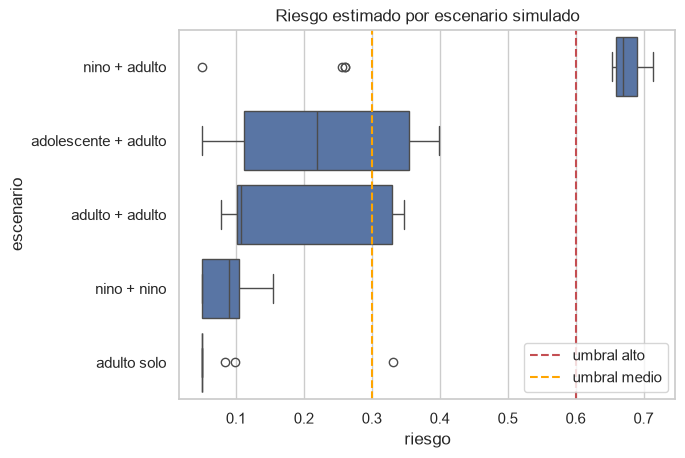

In [15]:
sns.boxplot(data=sim, x="riesgo", y="escenario", order=list(SCENARIOS))
plt.axvline(0.6, ls="--", c="r", label="umbral alto"); plt.axvline(0.3, ls="--", c="orange", label="umbral medio")
plt.legend(); plt.title("Riesgo estimado por escenario simulado"); plt.show()

## Conclusiones y siguientes pasos

- Revisa la tabla de la sección 6: típicamente **WavLM > ECAPA > acústico**, pero el notebook
  elige con los datos, no por suposición.
- Si en la auditoría de la sección 7 el recall de `nino` cae mucho con audio degradado, el modelo
  está usando atajos de canal (ENNI es habla sintetizada y limpia): añade corpus con niños y
  adultos en el mismo canal (speechocean762, MyST, CSLU Kids) a `construccion_dataset.ipynb`.
- Mejoras: diarización con pyannote, *fine-tuning* de WavLM con más datos de menores, más audio
  en español, calibrar umbrales con un conjunto de conversaciones reales anotadas.

**Despliegue**: `uvicorn api.main:app` o `docker compose up --build` (ver `README.md`).

> Recordatorio: el puntaje es una **alerta para priorizar revisión humana**, nunca una prueba ni una decisión.